**ФИО студента:** [Иванов Иван Иванович]

**Задание:** [выберите между `inpainting` / `outpainting`]

**Группа:** [номер группы]

**Дата сдачи:** [дата]

## Блок настройки окружения

Код для импорта библиотек, для формирования глобальных констант, других конфигураций (если требуется). Постарайтесь здесь зафиксировать все seed, которые сможете

In [88]:
import random

import hashlib
from pathlib import Path
import time

import ipywidgets as widgets
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, display
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"
MLFLOW_EXPERIMENT_NAME = "inpainting"
MLFLOW_MODEL_NAME = "inpainting_unet"

try:
    import mlflow
    from mlflow.exceptions import MlflowException
    from mlflow.tracking import MlflowClient

    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)
    MLFLOW_AVAILABLE = True
except Exception:
    MLFLOW_AVAILABLE = False

print(f"Трекинг MLflow: {'включен' if MLFLOW_AVAILABLE else 'отключен'}")


Трекинг MLflow: включен


In [89]:
device

device(type='cuda')

## Блок "Данные"

Входной файл проверяется по SHA-256, форме и заполнению области пропусков нулями: в данных пропуски хранятся как 0. Куб предзагружен в оперативную память (1 Гб), поэтому копирование патчей в датасете быстрее, чем чтение из mmap.

Пять соседних срезов дают модели 2.5D-контекст по глубине: центральный срез восстанавливается с учётом двух предыдущих и двух следующих. Патч 320×160 охватывает локальную геологическую структуру и ограничивает расход памяти. Синтетическая маска 213×103 соответствует размеру реальной скрытой области. Для train-выборки положение маски и отражения патчей варьируются, амплитуды масштабируются фактором из `AMP_SCALE_RANGE`, а в известные значения контекста добавляется гауссов шум с разбросом `NOISE_SIGMA`; целевой срез и канал маски остаются чистыми.

Разбиение выполнено по индексам центральных срезов, а не по отдельным пикселям. Между train, validation и test оставлены защитные интервалы, поэтому их пятисрезовые контексты не пересекаются и данные не протекают между выборками.
Параметры разбиения задаются переменными `TRAIN_RATIO`, `VAL_RATIO`, `TEST_RATIO`, `SPLIT_GAP` и `SLICE_RANGE`, размер батча и число воркеров — `BATCH_SIZE` и `NUM_WORKERS`.


In [90]:
DATA_PATH = Path("input_seismic_data/inpainting_cube_missed_data.npy")
EXPECTED_SHAPE = (580, 951, 462)
EXPECTED_SHA256 = "1aa956cfb12a75536ddd815f5d6f21abfbcccf474aec6de0d0a04c76b6eab1e5"

sha256 = hashlib.sha256()
with DATA_PATH.open("rb") as file:
    for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)

actual_sha256 = sha256.hexdigest()
assert actual_sha256 == EXPECTED_SHA256, (
    f"SHA-256 не совпадает: ожидался {EXPECTED_SHA256}, получен {actual_sha256}"
)

cube = np.load(DATA_PATH)
assert cube.shape == EXPECTED_SHAPE
assert cube.dtype == np.float32
print(cube.shape)

real_mask = np.zeros(cube.shape, dtype=bool)
real_mask[:, 368:581, 179:282] = True

for slice_index in range(cube.shape[0]):
    assert np.all(cube[slice_index][real_mask[slice_index]] == 0), (
        f"Область пропусков в срезе {slice_index} содержит ненулевые значения"
    )

missing_count = int(real_mask.sum())
print(
    f"Проверка нулей пройдена: {missing_count:,} пропущенных значений, "
    f"{100 * missing_count / cube.size:.2f}% куба"
)

PATCH_H = 320
PATCH_W = 160

MASK_H = 213
MASK_W = 103
REGIONS = (
    (0, 368, 0, 462),
    (581, 951, 0, 462),
    (0, 951, 0, 179),
    (0, 951, 282, 462)
)

AMP_SCALE_RANGE = (0.9, 1.1)
NOISE_SIGMA = 0.05


(580, 951, 462)
Проверка нулей пройдена: 12,724,620 пропущенных значений, 4.99% куба


In [91]:
sample = cube[::4, ::4, ::4]
sample_known = ~real_mask[::4, ::4, ::4]
mean = float(sample[sample_known].mean())
std = max(float(sample[sample_known].std()), 1e-6)


In [92]:
def make_samples(centers, samples_per_center, augment, seed):
    rng = np.random.default_rng(seed)
    samples = []

    for center in centers:
        for _ in range(samples_per_center):
            y_min, y_max, z_min, z_max = REGIONS[rng.integers(len(REGIONS))]
            y = int(rng.integers(y_min, y_max - PATCH_H + 1))
            z = int(rng.integers(z_min, z_max - PATCH_W + 1))
            mask_y = int(rng.integers(16, PATCH_H - MASK_H - 15))
            mask_z = int(rng.integers(16, PATCH_W - MASK_W - 15))
            flip_h = augment and bool(rng.integers(2))
            flip_v = augment and bool(rng.integers(2))
            amp_scale = float(rng.uniform(*AMP_SCALE_RANGE)) if augment else 1.0
            noise_sigma = float(rng.uniform(0.0, NOISE_SIGMA)) if augment else 0.0
            samples.append(
                (center, y, z, mask_y, mask_z, flip_h, flip_v, amp_scale, noise_sigma)
            )

    return samples


In [93]:
class InpaintingDataset(Dataset):
    def __init__(self, cube, samples, mean, std):
        self.cube = cube
        self.samples = samples
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        center, y, z, mask_y, mask_z, flip_h, flip_v, amp_scale, noise_sigma = self.samples[index]
        patch = self.cube[
            center - 2:center + 3,
            y:y + PATCH_H,
            z:z + PATCH_W
        ].copy()
        target = patch[2].copy()

        patch = (patch - self.mean) / self.std
        target = (target - self.mean) / self.std
        patch *= amp_scale
        target *= amp_scale
        if noise_sigma:
            noise = np.random.default_rng(index).standard_normal(patch.shape)
            patch += noise.astype(np.float32) * noise_sigma

        mask = np.zeros((PATCH_H, PATCH_W), dtype=np.float32)
        mask[mask_y:mask_y + MASK_H, mask_z:mask_z + MASK_W] = 1
        patch *= (1 - mask)[None]

        if flip_h:
            patch = patch[:, :, ::-1]
            target = target[:, ::-1]
            mask = mask[:, ::-1]

        if flip_v:
            patch = patch[:, ::-1, :]
            target = target[::-1, :]
            mask = mask[::-1, :]

        inputs = np.concatenate((patch, mask[None]), axis=0)

        return (
            torch.from_numpy(inputs.copy()).float(),
            torch.from_numpy(target[None].copy()).float(),
            torch.from_numpy(mask[None].copy()).float()
        )


In [94]:
TRAIN_RATIO = 0.88
VAL_RATIO = 0.05
TEST_RATIO = 0.07
SPLIT_GAP = 4
SLICE_RANGE = (2, 578)
TRAIN_SAMPLES_PER_CENTER = 4

ratios = np.array([TRAIN_RATIO, VAL_RATIO, TEST_RATIO])
ratios /= ratios.sum()
span = SLICE_RANGE[1] - SLICE_RANGE[0] - 2 * SPLIT_GAP
n_train = int(round(span * ratios[0]))
n_val = int(round(span * ratios[1]))
n_test = span - n_train - n_val
assert min(n_train, n_val, n_test) > 0

train_start = SLICE_RANGE[0]
val_start = train_start + n_train + SPLIT_GAP
test_start = val_start + n_val + SPLIT_GAP

train_centers = np.arange(train_start, train_start + n_train)
val_centers = np.arange(val_start, val_start + n_val)
test_centers = np.arange(test_start, test_start + n_test)
train_samples = make_samples(train_centers, TRAIN_SAMPLES_PER_CENTER, True, 42)
val_samples = make_samples(val_centers, 4, False, 43)
test_samples = make_samples(test_centers, 4, False, 44)

train_dataset = InpaintingDataset(cube, train_samples, mean, std)
val_dataset = InpaintingDataset(cube, val_samples, mean, std)
test_dataset = InpaintingDataset(cube, test_samples, mean, std)


In [95]:
BATCH_SIZE = 32
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


## Блок "Модель"

Используется полносвёрточная 2.5D U-Net: пять соседних срезов и маска пропусков подаются как шесть каналов. `AvgPool2d` сохраняет усреднённую структуру подписанных амплитуд вместо выбора только экстремумов. Для восстановления разрешения применяются nearest-интерполяция и свёртка 3×3, что исключает шахматочные артефакты транспонированной свёртки. GroupNorm стабилизирует обучение при небольшом batch size.


In [96]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(8, out_channels),
            nn.GELU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(8, out_channels),
            nn.GELU()
        )

    def forward(self, x):
        return self.block(x)


In [97]:
class UNet25D(nn.Module):
    def __init__(self, in_channels=6, out_channels=1, base_channels=32):
        super().__init__()
        self.pool = nn.AvgPool2d(2)
        self.encoders = nn.ModuleList([
            ConvBlock(in_channels, base_channels),
            ConvBlock(base_channels, base_channels * 2),
            ConvBlock(base_channels * 2, base_channels * 4),
            ConvBlock(base_channels * 4, base_channels * 8)
        ])
        self.bottleneck = ConvBlock(base_channels * 8, base_channels * 16)
        self.upconvs = nn.ModuleList([
            nn.Conv2d(base_channels * 16, base_channels * 8, 3, padding=1),
            nn.Conv2d(base_channels * 8, base_channels * 4, 3, padding=1),
            nn.Conv2d(base_channels * 4, base_channels * 2, 3, padding=1),
            nn.Conv2d(base_channels * 2, base_channels, 3, padding=1)
        ])
        self.decoders = nn.ModuleList([
            ConvBlock(base_channels * 16, base_channels * 8),
            ConvBlock(base_channels * 8, base_channels * 4),
            ConvBlock(base_channels * 4, base_channels * 2),
            ConvBlock(base_channels * 2, base_channels)
        ])
        self.head = nn.Conv2d(base_channels, out_channels, 1)

    def forward(self, x):
        height, width = x.shape[-2:]
        pad_height = (-height) % 16
        pad_width = (-width) % 16
        x = F.pad(x, (0, pad_width, 0, pad_height))

        skips = []
        for encoder in self.encoders:
            x = encoder(x)
            skips.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)

        for upconv, decoder, skip in zip(
            self.upconvs,
            self.decoders,
            reversed(skips)
        ):
            x = F.interpolate(x, scale_factor=2, mode="nearest")
            x = upconv(x)
            x = torch.cat((x, skip), dim=1)
            x = decoder(x)

        x = self.head(x)
        return x[..., :height, :width]


model = UNet25D()
print(f"Параметров модели: {sum(p.numel() for p in model.parameters()):,}")


Параметров модели: 8,634,305


## Блок "Обучение модели"

Функция потерь объединяет маскированные L1 и MSE (вес `L1_WEIGHT`) и дифференцируемый член `R_LOSS_WEIGHT · (1 − R)`, поэтому оптимизация напрямую учитывает целевую метрику корреляции. R считается глобально по всем маскированным значениям эпохи, поэтому метрики train, val и test сравнимы. Лучшая модель выбирается по глобальному validation R. История train и validation сохраняется в TensorBoard, выводится на статичных графиках loss и R и записывается в MLflow, если трекер доступен.

Задан лимит в `EPOCHS` эпох. Валидация, сохранение чекпоинта и ранняя остановка выполняются каждые `VALIDATION_EVERY` эпох, patience считается в циклах валидации. Для дообучения лучшего чекпоинта нужно установить `RESUME = True`: восстановятся веса, оптимизатор, scheduler, scaler, номер эпохи и история.


In [98]:
def masked_mse(prediction, target, mask):
    error = (prediction - target) ** 2
    return (error * mask).sum() / mask.sum().clamp_min(1)


def masked_l1(prediction, target, mask):
    error = torch.abs(prediction - target)
    return (error * mask).sum() / mask.sum().clamp_min(1)


def masked_gradient_l1(prediction, target, mask):
    mask_x = mask[..., 1:] * mask[..., :-1]
    mask_y = mask[1:] * mask[:-1]
    error_x = (prediction[..., 1:] - prediction[..., :-1] - target[..., 1:] + target[..., :-1]).abs()
    error_y = (prediction[1:] - prediction[:-1] - target[1:] + target[:-1]).abs()
    return (
        (error_x * mask_x).sum() + (error_y * mask_y).sum()
    ) / (mask_x.sum() + mask_y.sum()).clamp_min(1)


def correlation_r(prediction, target):
    prediction = prediction - prediction.mean()
    target = target - target.mean()
    denominator = prediction.norm() * target.norm()
    return (prediction * target).sum() / denominator.clamp_min(1e-8)


def masked_r(prediction, target, mask):
    return correlation_r(
        prediction[mask.bool()].float(),
        target[mask.bool()].float(),
    )


def reconstruction_loss(prediction, target, mask):
    l1_loss = masked_l1(prediction, target, mask)
    mse_loss = masked_mse(prediction, target, mask)
    grad_loss = masked_gradient_l1(prediction, target, mask)
    r_loss = 1 - masked_r(prediction, target, mask)
    return L1_WEIGHT * l1_loss + mse_loss + GRAD_LOSS_WEIGHT * grad_loss + R_LOSS_WEIGHT * r_loss


def new_r_moments():
    return torch.zeros(6, device=device)


def add_r_moments(moments, prediction, target, mask):
    prediction = prediction.detach()[mask.bool()].float()
    target = target[mask.bool()].float()
    update = torch.stack(
        (
            prediction.new_full((), float(prediction.numel())),
            prediction.sum(),
            target.sum(),
            (prediction * prediction).sum(),
            (target * target).sum(),
            (prediction * target).sum()
        )
    )
    return moments + update


def r_from_moments(moments):
    moments = moments.reshape(6)
    n = moments[0]
    sum_x = moments[1]
    sum_y = moments[2]
    sum_xx = moments[3]
    sum_yy = moments[4]
    sum_xy = moments[5]
    cov = n * sum_xy - sum_x * sum_y
    var_x = (n * sum_xx - sum_x * sum_x).clamp_min(1e-8)
    var_y = (n * sum_yy - sum_y * sum_y).clamp_min(1e-8)
    return (cov / (var_x.sqrt() * var_y.sqrt())).item()


In [99]:
%load_ext tensorboard
from torch.utils.tensorboard import SummaryWriter

model = model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4,
    min_lr=1e-5
)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

EPOCHS = 75
EARLY_STOPPING_PATIENCE = 12
VALIDATION_EVERY = 1
L1_WEIGHT = 1.0
R_LOSS_WEIGHT = 0.1
GRAD_LOSS_WEIGHT = 0.3
RESUME = False
CHECKPOINT_PATH = "best_inpainting_unet.pt"
RUN_STAMP = time.strftime("%Y-%m-%d_%H-%M-%S")
LOG_DIR = f"runs/inpainting/{RUN_STAMP}"
writer = SummaryWriter(LOG_DIR)
best_val_r = -float("inf")
start_epoch = 1
epochs_without_improvement = 0
history = {
    "train_loss": [],
    "val_loss": [],
    "train_r": [],
    "val_r": []
}

if RESUME:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    start_epoch = checkpoint["epoch"] + 1
    best_val_r = checkpoint["best_val_r"]
    history = checkpoint["history"]

if MLFLOW_AVAILABLE:
    if mlflow.active_run() is not None:
        mlflow.end_run()
    mlflow.start_run(run_name=f"epoch-{start_epoch}")
    mlflow.log_params(
        {
            "seed": SEED,
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "validation_every": VALIDATION_EVERY,
            "early_stopping_patience": EARLY_STOPPING_PATIENCE,
            "l1_weight": L1_WEIGHT,
            "r_loss_weight": R_LOSS_WEIGHT,
            "grad_loss_weight": GRAD_LOSS_WEIGHT,
            "train_samples_per_center": TRAIN_SAMPLES_PER_CENTER,
            "amp_scale_range": str(AMP_SCALE_RANGE),
            "noise_sigma": NOISE_SIGMA,
            "train_ratio": TRAIN_RATIO,
            "val_ratio": VAL_RATIO,
            "test_ratio": TEST_RATIO,
            "split_gap": SPLIT_GAP,
            "patch": f"{PATCH_H}x{PATCH_W}",
            "mask": f"{MASK_H}x{MASK_W}",
            "param_count": sum(p.numel() for p in model.parameters()),
        }
    )
    mlflow.set_tag("model/architecture", str(model))
    mlflow.set_tag("log_dir", LOG_DIR)


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard
🏃 View run epoch-1 at: http://127.0.0.1:5000/#/experiments/2/runs/1996a54753a043ae9703e43722ac06da
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [100]:
def train_epoch():
    model.train()
    total_loss = 0
    r_moments = new_r_moments()

    for inputs, target, mask in tqdm(train_loader, desc="train", leave=False):
        inputs = inputs.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=use_amp):
            prediction = model(inputs)
            loss = reconstruction_loss(prediction, target, mask)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * inputs.size(0)
        r_moments = add_r_moments(r_moments, prediction, target, mask)

    train_r = r_from_moments(r_moments)

    return total_loss / len(train_loader.dataset), train_r


In [101]:
def validation_epoch():
    model.eval()
    total_loss = 0
    r_moments = new_r_moments()

    with torch.inference_mode():
        for inputs, target, mask in tqdm(val_loader, desc="val", leave=False):
            inputs = inputs.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)

            with torch.autocast(device_type=device.type, enabled=use_amp):
                prediction = model(inputs)
                loss = reconstruction_loss(prediction, target, mask)

            total_loss += loss.item() * inputs.size(0)
            r_moments = add_r_moments(r_moments, prediction, target, mask)

    val_r = r_from_moments(r_moments)

    return total_loss / len(val_loader.dataset), val_r


In [102]:
pbar = tqdm(range(start_epoch, EPOCHS + 1))
for epoch in pbar:
    train_loss, train_r = train_epoch()

    history["train_loss"].append(train_loss)
    history["train_r"].append(train_r)
    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("R/train", train_r, epoch)
    writer.add_scalar("Learning rate", optimizer.param_groups[0]["lr"], epoch)

    if MLFLOW_AVAILABLE:
        mlflow.log_metric("lr", optimizer.param_groups[0]["lr"], step=epoch)

    postfix = {"train_loss": f"{train_loss:.4f}", "train_R": f"{train_r:.4f}"}

    if epoch % VALIDATION_EVERY == 0:
        val_loss, val_r = validation_epoch()
        scheduler.step(val_r)

        history["val_loss"].append(val_loss)
        history["val_r"].append(val_r)
        writer.add_scalar("Loss/validation", val_loss, epoch)
        writer.add_scalar("R/validation", val_r, epoch)

        if val_r > best_val_r:
            best_val_r = val_r
            epochs_without_improvement = 0
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "scaler_state_dict": scaler.state_dict(),
                    "mean": mean,
                    "std": std,
                    "epoch": epoch,
                    "best_val_r": best_val_r,
                    "history": history
                },
                CHECKPOINT_PATH
            )
        else:
            epochs_without_improvement += 1

        postfix["val_loss"] = f"{val_loss:.4f}"
        postfix["val_R"] = f"{val_r:.4f}"

        if MLFLOW_AVAILABLE:
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("train_r", train_r, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("val_r", val_r, step=epoch)
            mlflow.log_metric("best_val_r", best_val_r, step=epoch)

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            pbar.set_postfix(postfix)
            break

    writer.flush()
    pbar.set_postfix(postfix)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
best_epoch = checkpoint["epoch"]
writer.close()


 73%|███████▎  | 55/75 [26:17<09:33, 28.69s/it, train_loss=1.4677, train_R=0.5958, val_loss=1.6783, val_R=0.3575]


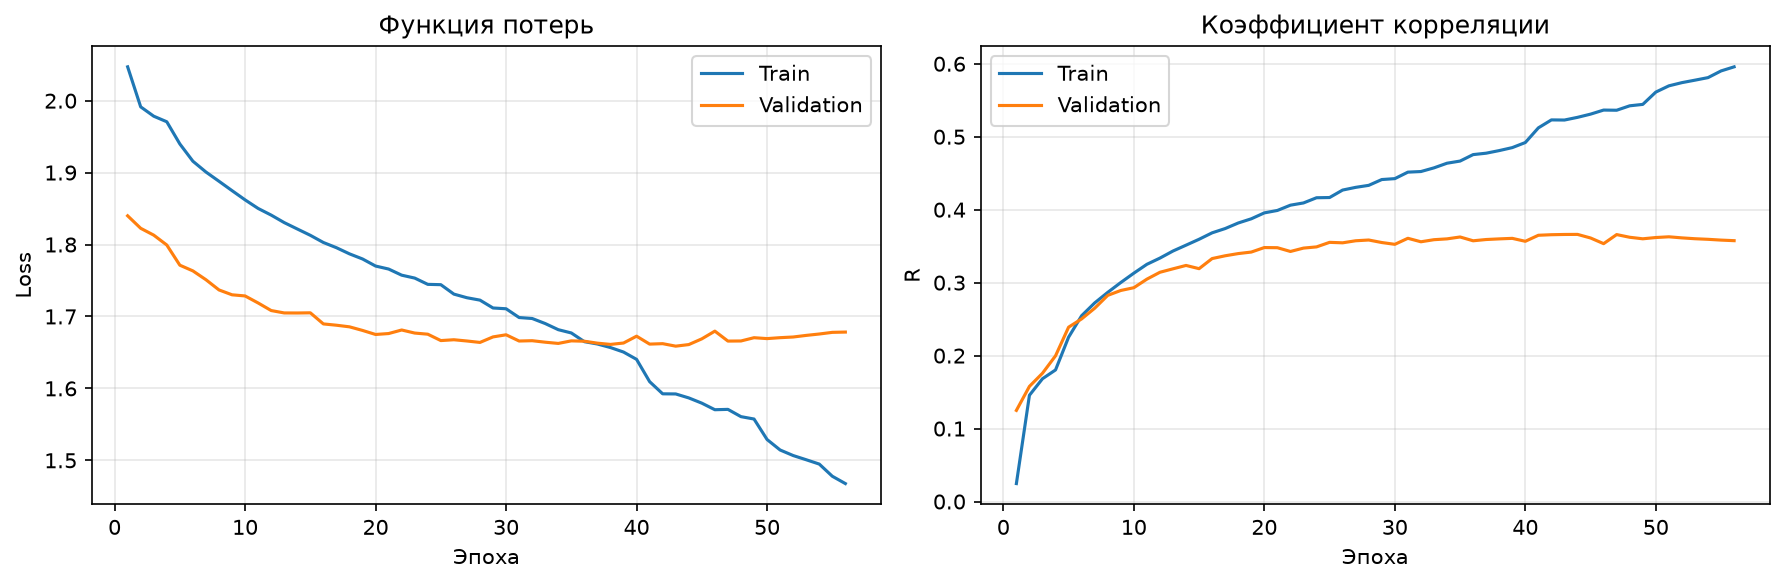

In [103]:
train_epochs = range(1, len(history["train_loss"]) + 1)
val_epochs = np.arange(
    VALIDATION_EVERY,
    len(history["val_loss"]) * VALIDATION_EVERY + 1,
    VALIDATION_EVERY
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_epochs, history["train_loss"], label="Train")
axes[0].plot(val_epochs, history["val_loss"], label="Validation")
axes[0].set(title="Функция потерь", xlabel="Эпоха", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(train_epochs, history["train_r"], label="Train")
axes[1].plot(val_epochs, history["val_r"], label="Validation")
axes[1].set(title="Коэффициент корреляции", xlabel="Эпоха", ylabel="R")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig("inpainting_training_history.png", dpi=150, bbox_inches="tight")
display(Image("inpainting_training_history.png"))


## Блок "Тестирование модели"

Модель загружается из чекпоинта `best_inpainting_unet.pt` (лучшая по валидационному R) и оценивается на тестовой выборке: средняя ошибка, коэффициент R и примеры предсказаний. При активном MLflow-запуске тестовые метрики и модель записываются на трекер, модель регистрируется в Model Registry, после чего запуск закрывается.


In [104]:
model = UNet25D().to(device)
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


UNet25D(
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (encoders): ModuleList(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(6, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
        (2): GELU(approximate='none')
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
        (5): GELU(approximate='none')
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
        (2): GELU(approximate='none')
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
        (5): GELU(approximate='none')
      )
    )
    (2): Con

In [ ]:
model.eval()
test_loss = 0
prediction_values = []
target_values = []

with torch.inference_mode():
    for inputs, target, mask in test_loader:
        inputs = inputs.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, enabled=use_amp):
            prediction = model(inputs)
            loss = reconstruction_loss(prediction, target, mask)

        test_loss += loss.item() * inputs.size(0)
        prediction_values.append(prediction[mask.bool()].float().cpu())
        target_values.append(target[mask.bool()].float().cpu())

test_loss /= len(test_loader.dataset)
test_predictions = torch.cat(prediction_values)
test_targets = torch.cat(target_values)
test_r = correlation_r(test_predictions, test_targets).item()

best_train_r = history["train_r"][best_epoch - 1] if history["train_r"] else 0
best_val_r = history["val_r"][best_epoch // VALIDATION_EVERY - 1] if history["val_r"] else 0
print(f"Test loss: {test_loss:.6f} | Test R: {test_r:.4f}")
print(
    f"Итоговые R | train: {best_train_r:.4f} | "
    f"val: {best_val_r:.4f} | test: {test_r:.4f}"
)

if MLFLOW_AVAILABLE and mlflow.active_run() is not None:
    mlflow.log_metric("test_loss", test_loss)
    mlflow.log_metric("test_r", test_r)
    model_info = mlflow.pytorch.log_model(
        model,
        artifact_path=MLFLOW_MODEL_NAME,
        serialization_format="pickle",
    )
    try:
        MlflowClient().create_registered_model(MLFLOW_MODEL_NAME)
    except MlflowException:
        pass
    MlflowClient().create_model_version(
        name=MLFLOW_MODEL_NAME,
        source=model_info.model_uri,
        run_id=mlflow.active_run().info.run_id,
        tags={"best-val-r": str(best_val_r)},
    )
    mlflow.end_run()


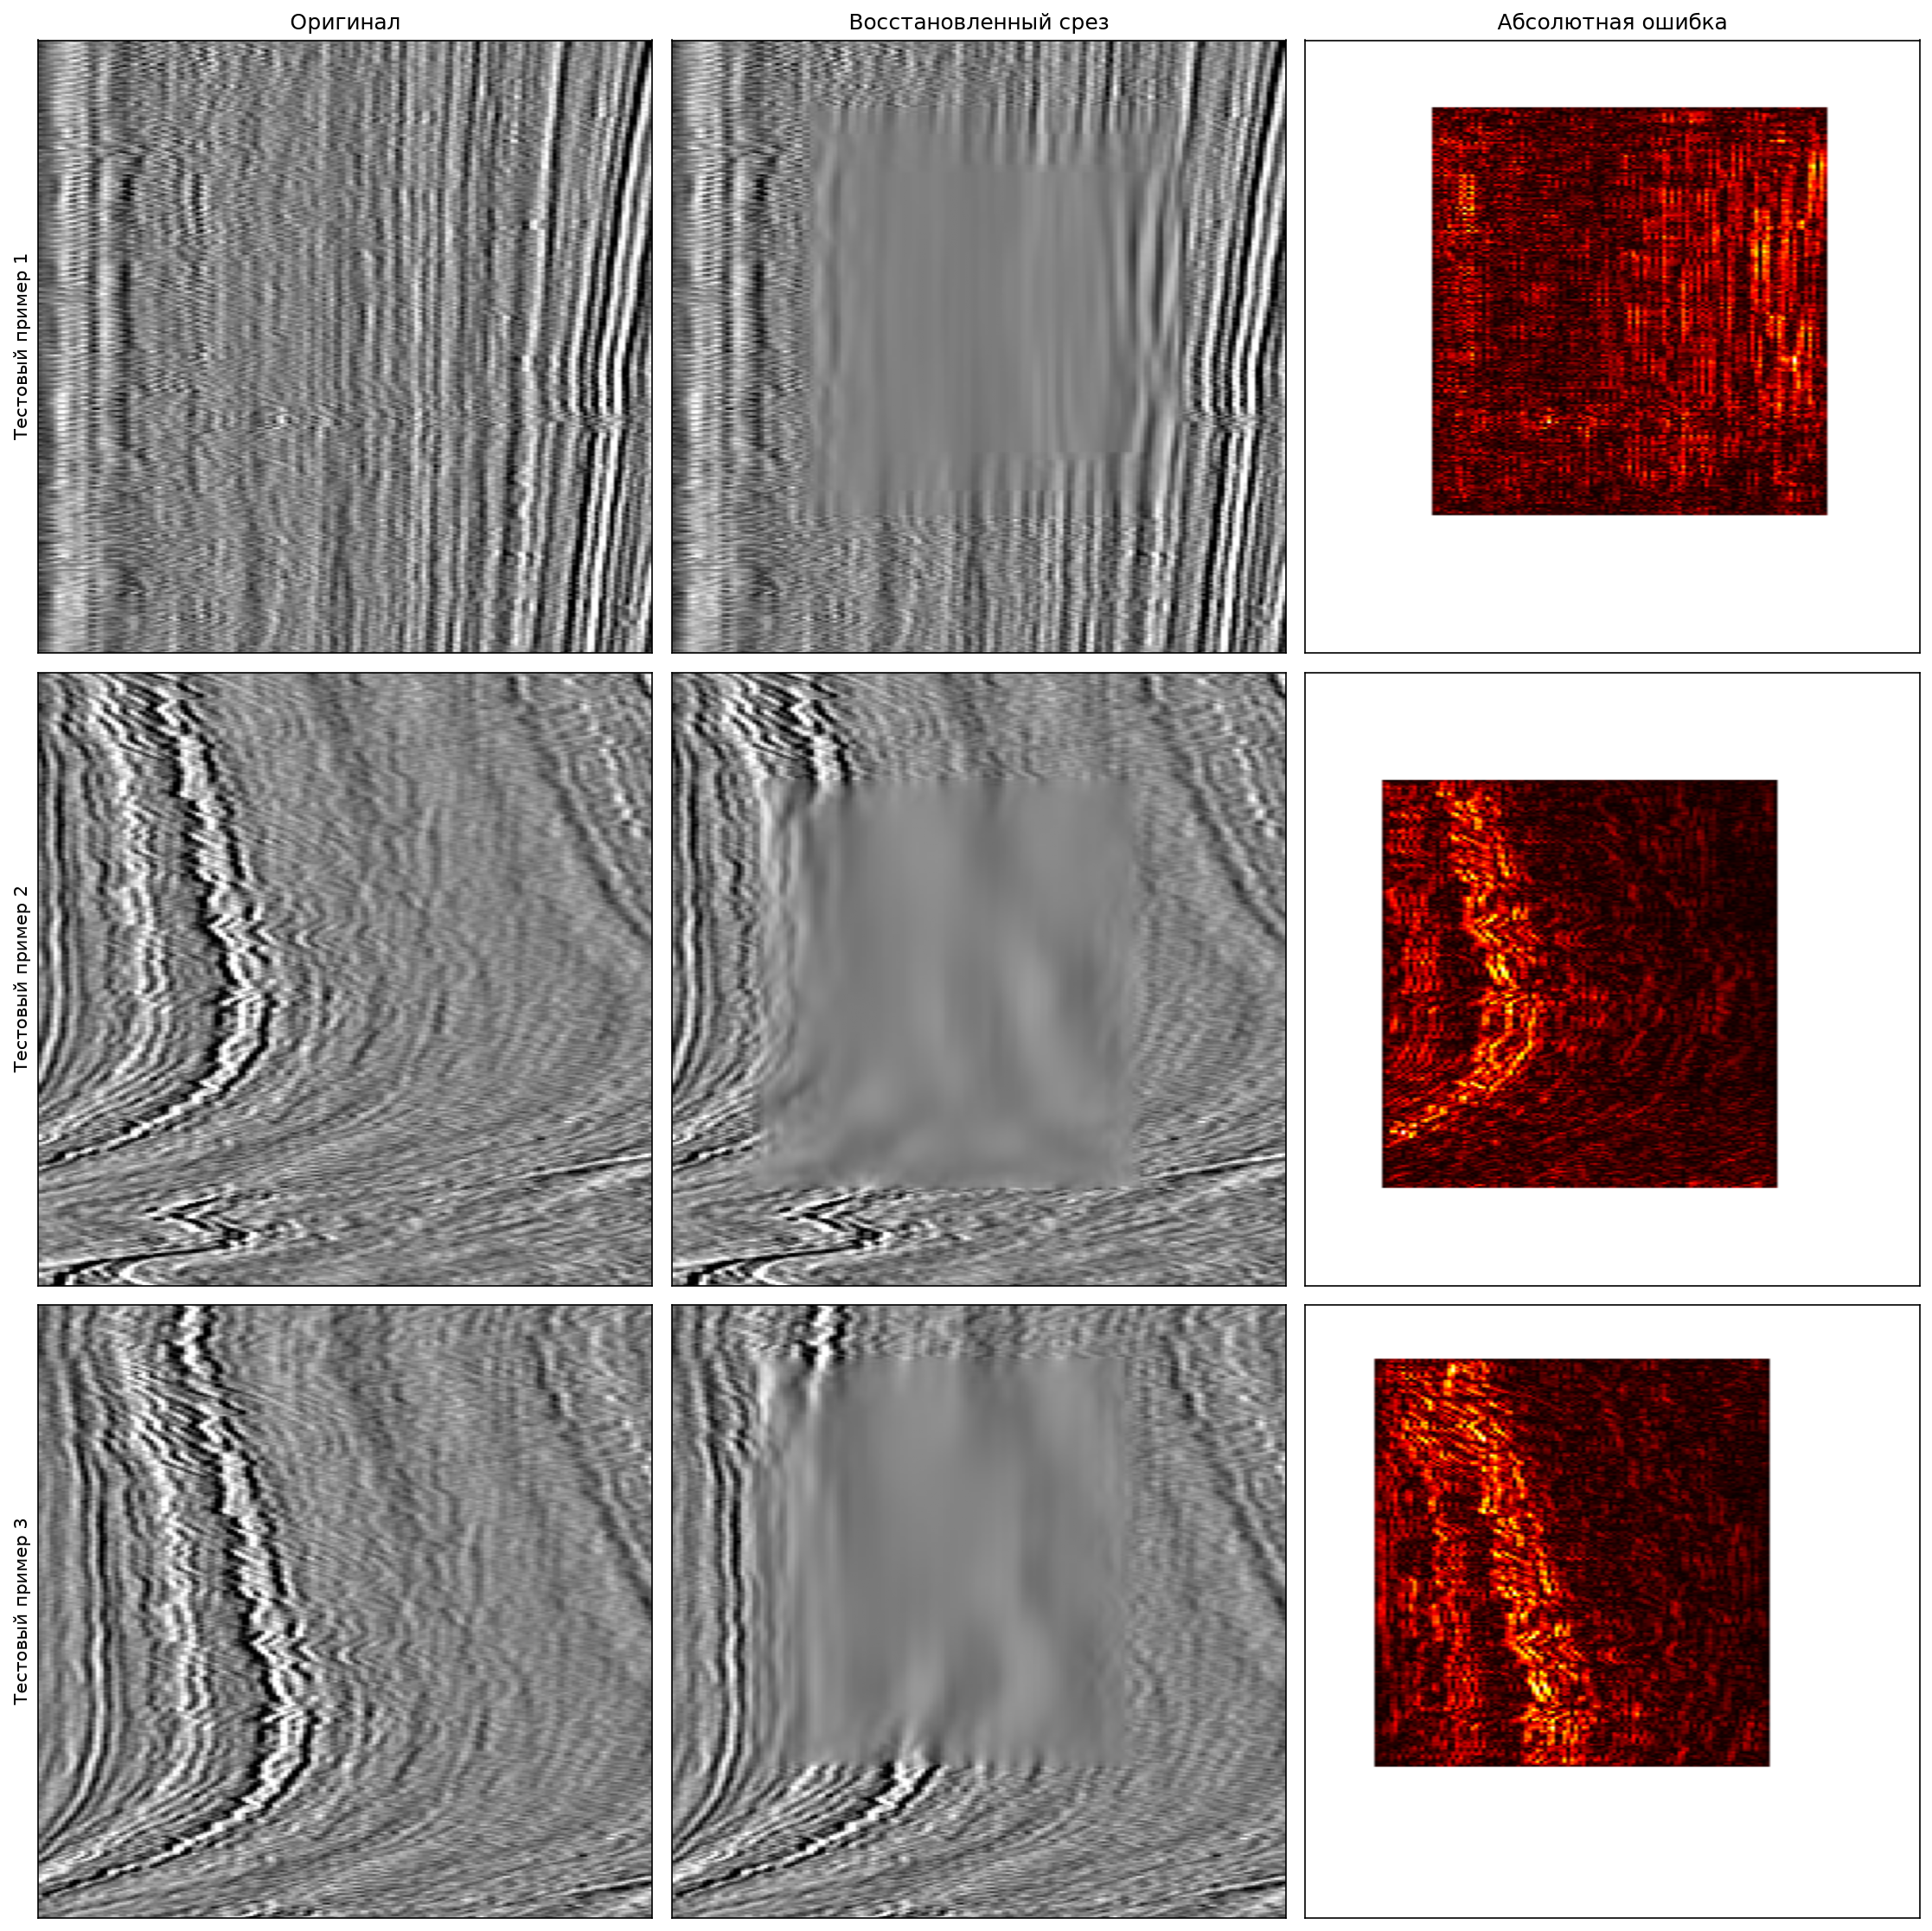

In [106]:
inputs, target, mask = next(iter(test_loader))
inputs = inputs.to(device)
target = target.to(device)
mask = mask.to(device)

with torch.inference_mode():
    with torch.autocast(device_type=device.type, enabled=use_amp):
        prediction = model(inputs)

examples = min(3, inputs.size(0))
fig, axes = plt.subplots(examples, 3, figsize=(15, 5 * examples))
titles = ("Оригинал", "Восстановленный срез", "Абсолютная ошибка")

for index in range(examples):
    original = target[index, 0].cpu().numpy() * std + mean
    predicted = prediction[index, 0].float().cpu().numpy() * std + mean
    sample_mask = mask[index, 0].cpu().numpy().astype(bool)

    restored = original.copy()
    restored[sample_mask] = predicted[sample_mask]

    error = np.full_like(original, np.nan)
    error[sample_mask] = np.abs(predicted[sample_mask] - original[sample_mask])

    a_min, a_max = np.percentile(original, [1, 99])
    panels = (
        (original, "gray", a_min, a_max),
        (restored, "gray", a_min, a_max),
        (error, "hot", None, None),
    )
    for column, (data, colormap, vmin, vmax) in enumerate(panels):
        axis = axes[index, column]
        axis.imshow(data, cmap=colormap, vmin=vmin, vmax=vmax, aspect="auto")
        axis.set_xticks([])
        axis.set_yticks([])

    axes[index, 0].set_ylabel(f"Тестовый пример {index + 1}")
    if index == 0:
        for column, title in enumerate(titles):
            axes[0, column].set_title(title)

fig.tight_layout()
fig.savefig("inpainting_test_examples.png", dpi=150, bbox_inches="tight")
display(Image("inpainting_test_examples.png"))


## Блок "Инференса модели"

Сеть полносвёрточная и использует локальные признаки, поэтому после обучения на патчах 320×160 применяется ко всему срезу 951×462. Вход дополняется до размеров, кратных 16, а результат обрезается до исходной формы.

На срезах 0, 1 и двух последних индексах несуществующие контекстные кадры заполняются нулями после нормализации. Это соответствует кодированию пропусков и не дублирует крайние кадры, чего не было в обучении.


In [107]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


def restore_slice(index):
    indices = np.arange(index - 2, index + 3)
    valid = (indices >= 0) & (indices < cube.shape[0])
    frames = np.zeros((5, *cube.shape[1:]), dtype=np.float32)
    frames[valid] = cube[indices[valid]]
    frames = (frames - mean) / std
    frames[~valid] = 0

    sample_mask = real_mask[index].astype(np.float32)
    frames *= (1 - sample_mask)[None]

    inputs = np.concatenate((frames, sample_mask[None]), axis=0)
    inputs = torch.from_numpy(inputs[None].copy()).float().to(device)

    with torch.inference_mode():
        with torch.autocast(device_type=device.type, enabled=use_amp):
            prediction = model(inputs)

    prediction = prediction[0, 0].float().cpu().numpy() * std + mean
    restored = cube[index].copy()
    restored[real_mask[index]] = prediction[real_mask[index]]
    return restored


In [108]:
def show_restored_slice(index):
    restored = restore_slice(index)
    original = cube[index].copy()
    missing = real_mask[index]

    original_display = original.copy()
    original_display[missing] = np.nan

    restored_region = np.full_like(restored, np.nan)
    restored_region[missing] = restored[missing]

    known = original[~missing]
    a_min, a_max = np.percentile(known, [1, 99])

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    panels = (
        (original_display, "Исходный срез"),
        (restored_region, "Восстановленная область"),
        (restored, "Результат"),
    )
    for column, (data, title) in enumerate(panels):
        axes[column].imshow(data, cmap="gray", vmin=a_min, vmax=a_max, aspect="auto")
        axes[column].set_title(title)
        axes[column].set_xticks([])
        axes[column].set_yticks([])

    fig.suptitle(f"Срез {index}")
    fig.tight_layout()
    fig.savefig("inpainting_restored_slice.png", dpi=150, bbox_inches="tight")
    display(Image("inpainting_restored_slice.png"))


In [ ]:
slice_slider = widgets.IntSlider(
    min=0,
    max=cube.shape[0] - 1,
    step=1,
    value=cube.shape[0] // 2,
    description="Срез",
    continuous_update=False
)

widgets.interact(show_restored_slice, index=slice_slider)


## Блок сохранения артефактов

Код и информация о том, как сохранялась модель и восстановленный куб (shape финального куба должен совпадать с shape'ом входного куба, который был скачан по ссылке)

In [109]:
restored_cube = cube.copy()

for index in tqdm(range(cube.shape[0])):
    restored_cube[index] = restore_slice(index)

assert restored_cube.shape == cube.shape

output_path = "inpainting_cube_restored.npy"
model_output_path = "inpainting_unet_inference.pt"
np.save(output_path, restored_cube)
torch.save(model.state_dict(), model_output_path)
print(f"Восстановленный куб сохранен: {output_path}")
print(f"Модель для инференса сохранена: {model_output_path}")


100%|██████████| 580/580 [00:29<00:00, 19.83it/s]


Восстановленный куб сохранен: inpainting_cube_restored.npy
Модель для инференса сохранена: inpainting_unet_inference.pt
